# Laborator 4 · Reducerea dimensionalității (PCA, LDA, t-SNE)
**Dataset:** Online Retail II (UCI) · **Metodologie:** CRISP-DM

| Fază CRISP-DM | Secțiune |
|---|---|
| 1. Înțelegerea sarcinii | 0 |
| 2. Înțelegerea datelor | 2 |
| 3. Pregătirea datelor | 3 |
| 4. Modelare | 4 (PCA, LDA, t-SNE) |
| 5. Evaluare | 5 |
| 6. Implementare | 6 (+ pagina Streamlit) |

## 0. Înțelegerea sarcinii (Business understanding)
**Întrebare:** putem rezuma *ce cumpără* fiecare client (sute de produse) în câteva dimensiuni, fără să pierdem informația utilă?

**De ce contează:** eficiență computațională, prevenirea supraantrenării, vizualizare în 2D/3D, reducerea zgomotului. Există și **blestemul dimensionalității**: cu multe dimensiuni, distanța euclidiană își pierde sensul și modelele se supraantrenează. Îl verificăm pe date, nu îl luăm de bun.

**Date:** matrice **client × produs** (câte unități din fiecare produs a cumpărat clientul în istoric), deci sute de dimensiuni. Etichetele pentru metodele supervizate (LDA) și pentru evaluare vin din comportamentul *viitor* (ultimele 90 de zile).

**Criterii de succes:**
1. **PCA:** câte componente rețin 95% din varianță și, separat, câte componente alege **validarea încrucișată** (pe train) pentru un model; comparăm cele două numere.
2. **LDA:** separare între clase **pe test**, nu doar pe train (în multe dimensiuni, LDA „învață pe de rost”).
3. **t-SNE:** păstrarea vecinătăților (trustworthiness) și structură vizibilă în 2D.

## 1. Setup

In [1]:
import json
import os
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from baza_date import (ARTEFACTE, SEED, construieste_clienti, curata, descrieri_produse, incarca_brut, salveaza_fig)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["PYTHONWARNINGS"] = "ignore"
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)

try:                                   # `display` există în Jupyter/VS Code; în terminal îl înlocuim cu print
    display
except NameError:
    def display(obj):
        print(obj)

PRAG_PRODUS = 0.02                     # păstrăm produsele cumpărate de cel puțin 2% dintre clienți
CLASE = {0: "fără cumpărare", 1: "cheltuială mică", 2: "cheltuială mare"}
CULORI = {0: "#7f7f7f", 1: "#1f77b4", 2: "#d62728"}

## 2. Înțelegerea datelor (Data understanding)
### 2.1 Încărcare și curățare
Aceeași încărcare și curățare ca în Laboratoarele 1–2 (cod comun în `baza_date.py`).

In [2]:
df = incarca_brut()
tranzactii, retururi, administrative, ajustari_stoc, contabilitate = curata(df)
contabilitate.to_csv(ARTEFACTE / "curatare.csv", index=False)
clienti, CUTOFF, istoric_v, viitor_v = construieste_clienti(tranzactii, retururi)
descriere = descrieri_produse(tranzactii)
display(contabilitate)
print(f"Data de tăiere: {CUTOFF.date()} | clienți cu istoric: {len(clienti)} | rânduri de istoric: {len(istoric_v):,}")

C:\Users\User\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,strat,rânduri,% din total
0,1. servicii/taxe/vouchere,5911,0.550
1,2. anulări (C),18286,1.710
2,3. preț/cantitate ≤ 0,6153,0.580
3,rămase: vânzări curate,1037021,97.160


Data de tăiere: 2011-09-10 | clienți cu istoric: 5256 | rânduri de istoric: 641,718


### 2.2 Matricea client × produs
Un rând = un client, o coloană = un produs, valoarea = unități cumpărate în **istoric** (înainte de data de tăiere; la fel ca la Laboratoarele 1–2, ca să nu folosim viitorul).
**Câte produse păstrăm?** Catalogul are mii de produse, multe cumpărate de foarte puțini clienți (coloane aproape goale, care aduc zgomot). Păstrăm produsele cumpărate de **cel puțin 2% dintre clienți** și măsurăm ce păstrăm (acoperirea rândurilor de istoric), ca decizia să aibă cifre.

In [3]:
n_clienti = istoric_v["Customer ID"].nunique()
clienti_per_produs = istoric_v.groupby("StockCode")["Customer ID"].nunique()
pastrate = clienti_per_produs[clienti_per_produs >= PRAG_PRODUS * n_clienti].index
sel = istoric_v[istoric_v["StockCode"].isin(pastrate)]
M = sel.groupby(["Customer ID", "StockCode"])["Quantity"].sum().unstack(fill_value=0).reindex(clienti.index, fill_value=0)
X_log = np.log1p(M.clip(lower=0)).astype("float32")          # log1p: cantitățile au coadă lungă (angrosiști)

rezumat_matrice = pd.DataFrame({
    "valoare": [len(clienti_per_produs), M.shape[1], M.shape[0], f"{(M.values == 0).mean():.1%}",
                f"{len(sel) / len(istoric_v):.1%}", f"{(M.sum(axis=1) == 0).sum()}"]},
    index=["produse în istoric", f"produse păstrate (≥ {PRAG_PRODUS:.0%} din clienți) = dimensiuni (D)", "clienți (rânduri)",
           "celule zero (raritate)", "rânduri de istoric acoperite de produsele păstrate", "clienți fără niciun produs păstrat"])
rezumat_matrice.to_csv(ARTEFACTE / "lab4_matrice.csv")
display(rezumat_matrice)

,valoare
produse în istoric,4445
produse păstrate (≥ 2% din clienți) = dimensiuni (D),1218
clienți (rânduri),5256
celule zero (raritate),95.5%
rânduri de istoric acoperite de produsele păstrate,78.8%
clienți fără niciun produs păstrat,62


### 2.3 Etichetele din viitor (pentru LDA și evaluare)
Trei clase de comportament în următoarele 90 de zile: **0** = nu cumpără; **1** = cumpără și cheltuiala netă ≤ mediana cumpărătorilor; **2** = cheltuială netă peste mediană. Mediana e calculată doar pe cumpărători, ca clasele 1 și 2 să fie egale ca mărime. (LDA dă cel mult *clase − 1* axe: cu 3 clase obținem 2 axe, deci un grafic 2D.)

In [4]:
cumparator = clienti["a_cumparat"]
mediana = clienti.loc[cumparator, "tinta_cheltuiala"].median()
clasa = pd.Series(0, index=clienti.index, name="clasa")
clasa[cumparator & (clienti["tinta_cheltuiala"] <= mediana)] = 1
clasa[cumparator & (clienti["tinta_cheltuiala"] > mediana)] = 2
dist_clase = clasa.map(CLASE).value_counts().rename("clienți").to_frame()
dist_clase["%"] = dist_clase["clienți"] / len(clasa) * 100
dist_clase.to_csv(ARTEFACTE / "lab4_clase.csv")
print(f"Mediana cheltuielii nete a cumpărătorilor: {mediana:,.2f} £")
display(dist_clase)

Mediana cheltuielii nete a cumpărătorilor: 521.20 £


,clienți,%
clasa,,
fără cumpărare,2967,56.450
cheltuială mică,1145,21.785
cheltuială mare,1144,21.766


## 3. Pregătirea datelor (Data preparation)
- **Împărțire 80/20 stratificată** (după clasă) **înainte** de orice scalare sau PCA: scalerul și componentele se învață doar pe train, altfel testul „vede” datele.
- **Standardizare z-score:** componentele PCA sunt sensibile la scara variabilelor, iar fără standardizare produsele vândute în cantități mari ar domina.
- **Blestemul dimensionalității:** înainte de modele, măsurăm cum se comportă distanța euclidiană când adăugăm dimensiuni (coeficientul de variație al distanțelor dintre perechi de clienți: dacă scade, toate distanțele devin asemănătoare și „cel mai apropiat vecin” nu mai spune nimic).

Train: (4204, 1218) | Test: (1052, 1218) | dimensiuni D = 1218


,distanța medie,abatere standard,coef. de variație
dimensiuni,,,
2,0.709,1.895,2.671
5,1.602,2.932,1.829
10,2.571,3.670,1.428
20,4.265,4.559,1.069
50,7.899,5.705,0.722
100,11.906,7.318,0.615
200,17.399,9.880,0.568
400,24.830,13.340,0.537
1218,43.875,22.664,0.517


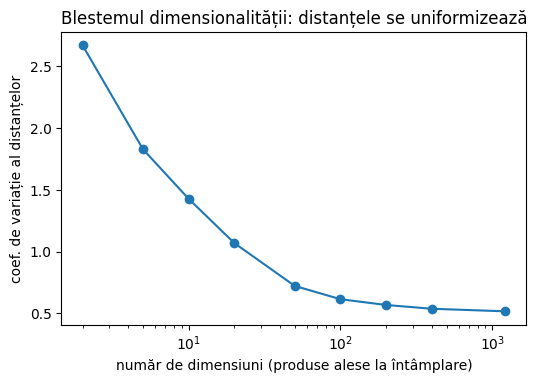

In [5]:
poz_tr, poz_te = train_test_split(np.arange(len(clienti)), test_size=0.2, stratify=clasa.to_numpy(), random_state=SEED)
idx_tr, idx_te = clienti.index[poz_tr], clienti.index[poz_te]
X_tr, X_te = X_log.loc[idx_tr], X_log.loc[idx_te]
y_tr, y_te = clasa.loc[idx_tr].to_numpy(), clasa.loc[idx_te].to_numpy()
scaler = StandardScaler().fit(X_tr)
Z_tr, Z_te, Z_all = scaler.transform(X_tr), scaler.transform(X_te), scaler.transform(X_log)
D = Z_tr.shape[1]
print(f"Train: {Z_tr.shape} | Test: {Z_te.shape} | dimensiuni D = {D}")

rng = np.random.default_rng(SEED)
esantion = rng.choice(len(Z_tr), size=min(1000, len(Z_tr)), replace=False)
ordine = rng.permutation(D)
dims = sorted({d for d in [2, 5, 10, 20, 50, 100, 200, 400, D] if d <= D})
concentrare = []
for d in dims:
    dist = pdist(Z_tr[esantion][:, ordine[:d]])
    concentrare.append({"dimensiuni": d, "distanța medie": dist.mean(), "abatere standard": dist.std(),
                        "coef. de variație": dist.std() / dist.mean()})
concentrare = pd.DataFrame(concentrare).set_index("dimensiuni")
concentrare.to_csv(ARTEFACTE / "lab4_blestem.csv")
display(concentrare)

plt.figure(figsize=(6, 3.8))
plt.plot(concentrare.index, concentrare["coef. de variație"], "o-"); plt.xscale("log")
plt.xlabel("număr de dimensiuni (produse alese la întâmplare)"); plt.ylabel("coef. de variație al distanțelor")
plt.title("Blestemul dimensionalității: distanțele se uniformizează")
salveaza_fig("lab4_blestem")

## 4. Modelare (Modeling)
### 4.1 PCA, pas cu pas
1. standardizare (făcută) → 2. matricea de covarianță `C = ZᵀZ/(n−1)` → 3. valori și vectori proprii (`Cx = λx`) → 4. ordonăm descrescător după λ și păstrăm primii *k* care explică ≥ 95% din varianță → 5. proiecția `X̂ = XW`.
Facem pașii 2–3 „de mână” cu `numpy` și verificăm că dau aceleași valori proprii ca `sklearn.PCA`.

,λ manual (numpy),λ sklearn PCA
PC1,101.141,101.141
PC2,26.425,26.425
PC3,15.818,15.818
PC4,14.323,14.323
PC5,12.569,12.569


Diferență maximă (primele 5): 1.8814858549376368e-05


,componente necesare,% din D
80% din varianță,426,34.975
90% din varianță,638,52.381
95% din varianță,813,66.749
99% din varianță,1069,87.767


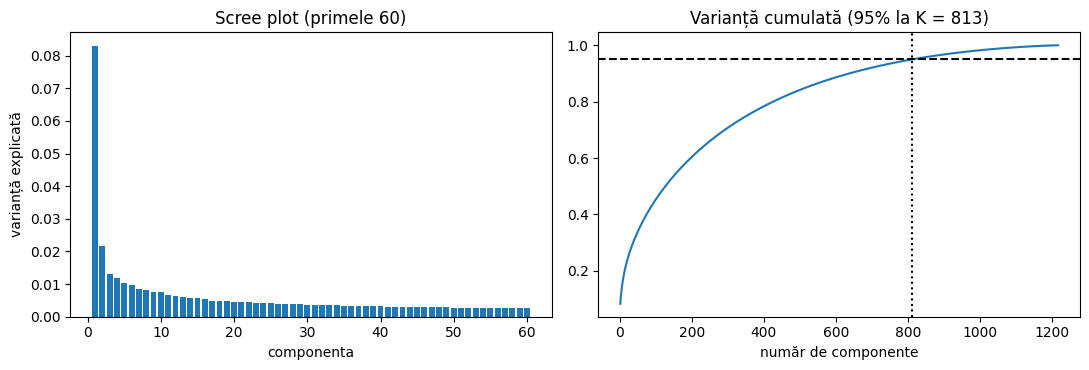

In [6]:
pca_full = PCA(random_state=SEED).fit(Z_tr)
valori_proprii = np.linalg.eigvalsh(np.cov(Z_tr, rowvar=False))[::-1]          # pașii 2–3 manual
verificare = pd.DataFrame({"λ manual (numpy)": valori_proprii[:5], "λ sklearn PCA": pca_full.explained_variance_[:5]})
verificare.index = [f"PC{i + 1}" for i in range(5)]
verificare.to_csv(ARTEFACTE / "lab4_verificare_pca.csv")
display(verificare)
print("Diferență maximă (primele 5):", float(np.abs(valori_proprii[:5] - pca_full.explained_variance_[:5]).max()))

cum = np.cumsum(pca_full.explained_variance_ratio_)
K = {p: int(np.searchsorted(cum, p) + 1) for p in [0.80, 0.90, 0.95, 0.99]}
K95 = K[0.95]
varianta = pd.DataFrame({"componenta": np.arange(1, len(cum) + 1), "varianță explicată": pca_full.explained_variance_ratio_, "cumulat": cum})
varianta.head(200).to_csv(ARTEFACTE / "lab4_pca_varianta.csv", index=False)
prag_tabel = pd.DataFrame({"componente necesare": K, "% din D": {p: k / D * 100 for p, k in K.items()}})
prag_tabel.index = [f"{p:.0%} din varianță" for p in K]
prag_tabel.to_csv(ARTEFACTE / "lab4_pca_praguri.csv")
display(prag_tabel)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
n_afis = min(60, len(cum))
ax[0].bar(range(1, n_afis + 1), pca_full.explained_variance_ratio_[:n_afis]); ax[0].set_title("Scree plot (primele 60)")
ax[0].set_xlabel("componenta"); ax[0].set_ylabel("varianță explicată")
ax[1].plot(range(1, len(cum) + 1), cum); ax[1].axhline(0.95, color="k", ls="--"); ax[1].axvline(K95, color="k", ls=":")
ax[1].set_title(f"Varianță cumulată (95% la K = {K95})"); ax[1].set_xlabel("număr de componente")
plt.tight_layout()
salveaza_fig("lab4_pca_scree")

**Ce înseamnă componentele?** Fiecare componentă e o combinație liniară de produse. Cele mai mari încărcări (în valoare absolută) arată ce produse o definesc.

In [7]:
nume_produse = descriere.reindex(M.columns).fillna("(fără descriere)")
incarcari = pd.DataFrame(pca_full.components_[:2].T, index=M.columns, columns=["PC1", "PC2"])
incarcari.insert(0, "produs", nume_produse.values)
incarcari.to_csv(ARTEFACTE / "lab4_incarcari.csv")
top = pd.concat([incarcari.reindex(incarcari["PC1"].abs().nlargest(8).index).assign(componenta="PC1"),
                 incarcari.reindex(incarcari["PC2"].abs().nlargest(8).index).assign(componenta="PC2")])
display(top[["componenta", "produs", "PC1", "PC2"]])
print("Proporția încărcărilor PC1 cu același semn:", f"{max((incarcari['PC1'] > 0).mean(), (incarcari['PC1'] < 0).mean()):.0%}")

,componenta,produs,PC1,PC2
StockCode,,,,
20725,PC1,LUNCH BAG RED RETROSPOT,0.054,0.033
22382,PC1,LUNCH BAG SPACEBOY DESIGN,0.051,0.049
21212,PC1,PACK OF 72 RETROSPOT CAKE CASES,0.050,0.032
22384,PC1,LUNCH BAG PINK POLKADOT,0.050,0.025
20728,PC1,LUNCH BAG CARS BLUE,0.050,0.029
20726,PC1,LUNCH BAG WOODLAND,0.048,0.053
20685,PC1,DOORMAT RED RETROSPOT,0.048,-0.026
23207,PC1,LUNCH BAG ALPHABET DESIGN,0.048,0.040
22326,PC2,ROUND SNACK BOXES SET OF4 WOODLAND,0.040,0.086


Proporția încărcărilor PC1 cu același semn: 100%


### 4.2 Câte componente păstrăm? Regula de 95% vs. validarea încrucișată
Regula „95% din varianță” e o convenție: nu ține cont de ce vrem să facem cu datele. O comparăm cu o alegere bazată pe **performanță**: pentru fiecare *k* dintr-o grilă, antrenăm `Scalare → PCA(k) → regresie logistică` cu **validare încrucișată 3-fold doar pe train** (PCA se reface în interiorul fiecărui fold, deci nu există scurgere) și alegem *k* cu **AUC macro one-vs-rest** maxim. Testul rămâne neatins până la 4.3.

,AUC validare (medie),abatere standard
k,,
2,0.716,0.005
5,0.723,0.004
10,0.728,0.001
20,0.730,0.004
50,0.727,0.005
100,0.712,0.009
200,0.704,0.005
813,0.609,0.004


k ales prin validare = 20 | k după regula de 95% = 813 | D = 1218


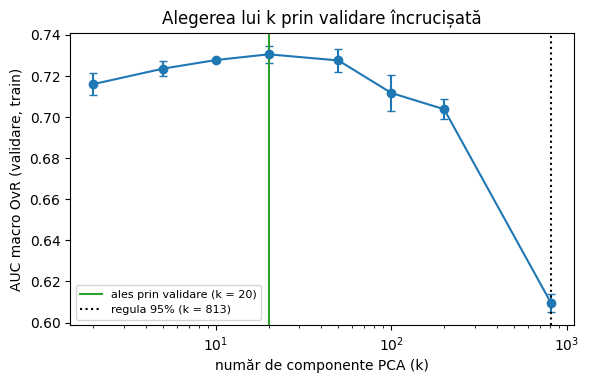

In [8]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
grila_k = sorted({k for k in [2, 5, 10, 20, 50, 100, 200, K95] if k <= D})
rez_cv = []
for k in grila_k:
    pipe = Pipeline([("scalare", StandardScaler()), ("pca", PCA(n_components=k, random_state=SEED)),
                     ("lr", LogisticRegression(max_iter=3000))])
    sc = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="roc_auc_ovr")
    rez_cv.append({"k": k, "AUC validare (medie)": sc.mean(), "abatere standard": sc.std()})
rez_cv = pd.DataFrame(rez_cv).set_index("k")
KCV = int(rez_cv["AUC validare (medie)"].idxmax())
rez_cv.to_csv(ARTEFACTE / "lab4_cv_k.csv")
display(rez_cv)
print(f"k ales prin validare = {KCV} | k după regula de 95% = {K95} | D = {D}")

plt.figure(figsize=(6.5, 3.8))
plt.errorbar(rez_cv.index, rez_cv["AUC validare (medie)"], yerr=rez_cv["abatere standard"], fmt="o-", capsize=3)
plt.axvline(KCV, color="tab:green", ls="-", label=f"ales prin validare (k = {KCV})")
plt.axvline(K95, color="k", ls=":", label=f"regula 95% (k = {K95})")
plt.xscale("log"); plt.xlabel("număr de componente PCA (k)"); plt.ylabel("AUC macro OvR (validare, train)")
plt.legend(fontsize=8); plt.title("Alegerea lui k prin validare încrucișată")
salveaza_fig("lab4_alegere_k")

### 4.3 Performanța unui model în funcție de numărul de dimensiuni
Performanța modelului nu crește la nesfârșit cu dimensiunile. Verificăm: antrenăm două modele pe primele *k* componente (și pe toate cele D variabile standardizate) și măsurăm **AUC macro one-vs-rest** pe train și pe test pentru cele 3 clase.
- **Regresia logistică** (liniară): un decalaj mare train − test = supraantrenare.
- **KNN** (K=15, bazat pe distanță): cel mai afectat de blestemul dimensionalității.
Baza (ce obținem fără nicio informație): AUC = 0,5.

,LogReg AUC train,LogReg AUC test,KNN AUC train,KNN AUC test
dimensiuni,,,,
2,0.717,0.711,0.770,0.688
5,0.723,0.713,0.782,0.675
10,0.734,0.720,0.787,0.691
20,0.740,0.725,0.791,0.688
50,0.749,0.730,0.797,0.661
100,0.760,0.717,0.792,0.646
200,0.781,0.696,0.795,0.636
813,0.897,0.624,0.819,0.621
1218 (toate),0.964,0.600,0.837,0.603


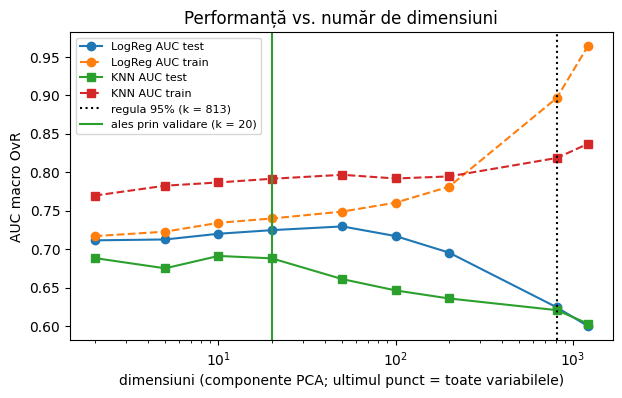

In [9]:
def auc3(model, A, y):
    return roc_auc_score(y, model.predict_proba(A), multi_class="ovr", average="macro")


T_tr, T_te = pca_full.transform(Z_tr), pca_full.transform(Z_te)
ks = grila_k
rez = []
for k in ks + [D]:
    A_tr, A_te = (T_tr[:, :k], T_te[:, :k]) if k != D else (Z_tr, Z_te)
    lr = LogisticRegression(max_iter=3000).fit(A_tr, y_tr)
    kn = KNeighborsClassifier(n_neighbors=15).fit(A_tr, y_tr)
    rez.append({"dimensiuni": k if k != D else f"{D} (toate)", "k": k, "LogReg AUC train": auc3(lr, A_tr, y_tr), "LogReg AUC test": auc3(lr, A_te, y_te),
                "KNN AUC train": auc3(kn, A_tr, y_tr), "KNN AUC test": auc3(kn, A_te, y_te)})
rez = pd.DataFrame(rez).set_index("dimensiuni")
rez.to_csv(ARTEFACTE / "lab4_performanta_dimensiuni.csv")
display(rez.drop(columns="k"))

plt.figure(figsize=(7, 4))
for col, st in [("LogReg AUC test", "o-"), ("LogReg AUC train", "o--"), ("KNN AUC test", "s-"), ("KNN AUC train", "s--")]:
    plt.plot(rez["k"], rez[col], st, label=col)
plt.xscale("log"); plt.xlabel("dimensiuni (componente PCA; ultimul punct = toate variabilele)"); plt.ylabel("AUC macro OvR")
plt.axvline(K95, color="k", ls=":", label=f"regula 95% (k = {K95})"); plt.axvline(KCV, color="tab:green", label=f"ales prin validare (k = {KCV})")
plt.legend(fontsize=8); plt.title("Performanță vs. număr de dimensiuni")
salveaza_fig("lab4_performanta_dimensiuni")

### 4.4 LDA (supervizat)
**Diferența față de PCA:** PCA nu folosește etichetele și caută direcția de **varianță maximă**; LDA le folosește și caută direcțiile care **maximizează distanța dintre mediile claselor și minimizează variația din interiorul lor**. Presupune clase gaussiene cu aceeași covarianță. Cu 3 clase obținem 2 axe (LD1, LD2).
**Verificarea blestemului:** antrenăm LDA (a) direct pe toate cele D variabile și (b) după PCA (k ales prin validare și k după regula de 95%). Comparăm acuratețea pe train și pe test, față de baza „clasa majoritară”.

In [10]:
baza_acc = DummyClassifier(strategy="most_frequent").fit(Z_tr, y_tr).score(Z_te, y_te)
NUME_LDA = f"PCA({KCV}) → LDA"
variante = {f"LDA pe toate cele {D} variabile": None, NUME_LDA: KCV}
if K95 != KCV:
    variante[f"PCA({K95}) → LDA"] = K95
rez_lda, modele_lda = [], {}
for nume, k in variante.items():
    pas = [("lda", LinearDiscriminantAnalysis(n_components=2))]
    if k is not None:
        pas.insert(0, ("pca", PCA(n_components=k, random_state=SEED)))
    mod = Pipeline(pas).fit(Z_tr, y_tr)
    modele_lda[nume] = mod
    rez_lda.append({"variantă": nume, "acuratețe train": mod.score(Z_tr, y_tr), "acuratețe test": mod.score(Z_te, y_te),
                    "AUC test": auc3(mod, Z_te, y_te)})
rez_lda = pd.DataFrame(rez_lda).set_index("variantă")
rez_lda["bază (clasa majoritară)"] = baza_acc
rez_lda.to_csv(ARTEFACTE / "lab4_lda.csv")
display(rez_lda)

,acuratețe train,acuratețe test,AUC test,bază (clasa majoritară)
variantă,,,,
LDA pe toate cele 1218 variabile,0.803,0.581,0.624,0.565
PCA(20) → LDA,0.636,0.626,0.712,0.565
PCA(813) → LDA,0.752,0.593,0.641,0.565


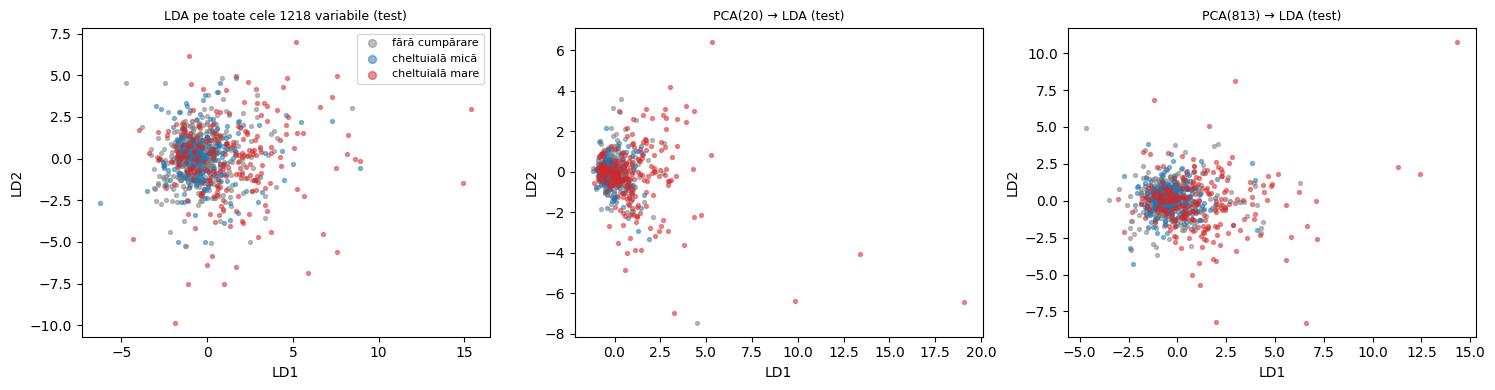

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharex=False, sharey=False)
for a, (nume, mod) in zip(ax, modele_lda.items()):
    P = mod.transform(Z_te) if len(mod.steps) == 1 else mod.named_steps["lda"].transform(mod.named_steps["pca"].transform(Z_te))
    for c in CLASE:
        m = y_te == c
        a.scatter(P[m, 0], P[m, 1], s=8, alpha=0.5, color=CULORI[c], label=CLASE[c])
    a.set_title(nume + " (test)", fontsize=9); a.set_xlabel("LD1"); a.set_ylabel("LD2")
ax[0].legend(markerscale=2, fontsize=8)
plt.tight_layout()
salveaza_fig("lab4_lda")

### 4.5 t-SNE (neliniar, doar pentru vizualizare)
**Cum funcționează:** (1) similarități între puncte în spațiul mare, cu distribuții gaussiene centrate pe fiecare punct; (2) similarități în spațiul 2D, cu distribuția t-Student; (3) minimizează divergența Kullback-Leibler dintre cele două.
**Practică uzuală:** nu rulăm t-SNE pe toate cele D dimensiuni, ci pe primele **50 de componente PCA** (mai rapid și mai puțin zgomot).
**Perplexity** = câți vecini „contează” pentru fiecare punct; o testăm la 5, 30 și 50. Comparăm rezultatele cu **trustworthiness** (între 0 și 1: cât de bine rămân vecinii din spațiul mare vecini și în 2D) și cu KL, plus PCA 2D ca bază.
t-SNE se potrivește pe toți clienții (nu are `transform` pentru clienți noi) și e doar pentru vizualizare.

,KL divergență,trustworthiness (10 vecini)
perplexity,,
5,2.437,0.819
30,2.376,0.829
50,2.217,0.826
PCA 2D (bază),NaN,0.598


Perplexity ales (trustworthiness maximă): 30


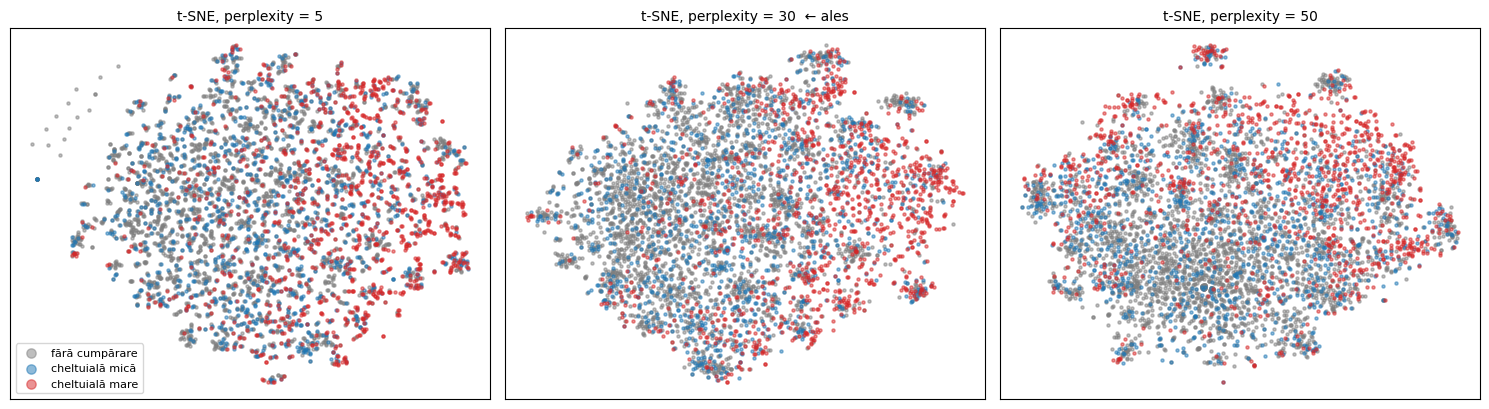

In [12]:
pca50 = PCA(n_components=min(50, D), random_state=SEED).fit(Z_tr)
P50 = pca50.transform(Z_all)
rez_ts, emb = [], {}
for perp in [5, 30, 50]:
    ts = TSNE(n_components=2, perplexity=perp, init="pca", learning_rate="auto", max_iter=1000, random_state=SEED)
    emb[perp] = ts.fit_transform(P50)
    rez_ts.append({"perplexity": perp, "KL divergență": ts.kl_divergence_, "trustworthiness (10 vecini)": trustworthiness(P50, emb[perp], n_neighbors=10)})
pca2_all = PCA(n_components=2, random_state=SEED).fit(Z_tr).transform(Z_all)
rez_ts.append({"perplexity": "PCA 2D (bază)", "KL divergență": np.nan, "trustworthiness (10 vecini)": trustworthiness(P50, pca2_all, n_neighbors=10)})
rez_ts = pd.DataFrame(rez_ts).set_index("perplexity")
rez_ts.to_csv(ARTEFACTE / "lab4_tsne.csv")
PERP = int(rez_ts.iloc[:3]["trustworthiness (10 vecini)"].idxmax())
display(rez_ts)
print("Perplexity ales (trustworthiness maximă):", PERP)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, perp in zip(ax, emb):
    for c in CLASE:
        m = (clasa.to_numpy() == c)
        a.scatter(emb[perp][m, 0], emb[perp][m, 1], s=5, alpha=0.5, color=CULORI[c], label=CLASE[c])
    a.set_title(f"t-SNE, perplexity = {perp}" + ("  ← ales" if perp == PERP else ""), fontsize=10); a.set_xticks([]); a.set_yticks([])
ax[0].legend(markerscale=3, fontsize=8)
plt.tight_layout()
salveaza_fig("lab4_tsne")

## 5. Evaluare (Evaluation)
### 5.1 Comparația metodelor în 2D
Aceleași puncte (toți clienții), colorate după clasa de comportament viitor. **Atenție:** culorile *nu* au fost folosite de PCA și t-SNE (nesupervizate); LDA le-a folosit pe train, deci îl judecăm pe test (tabelul 4.4).

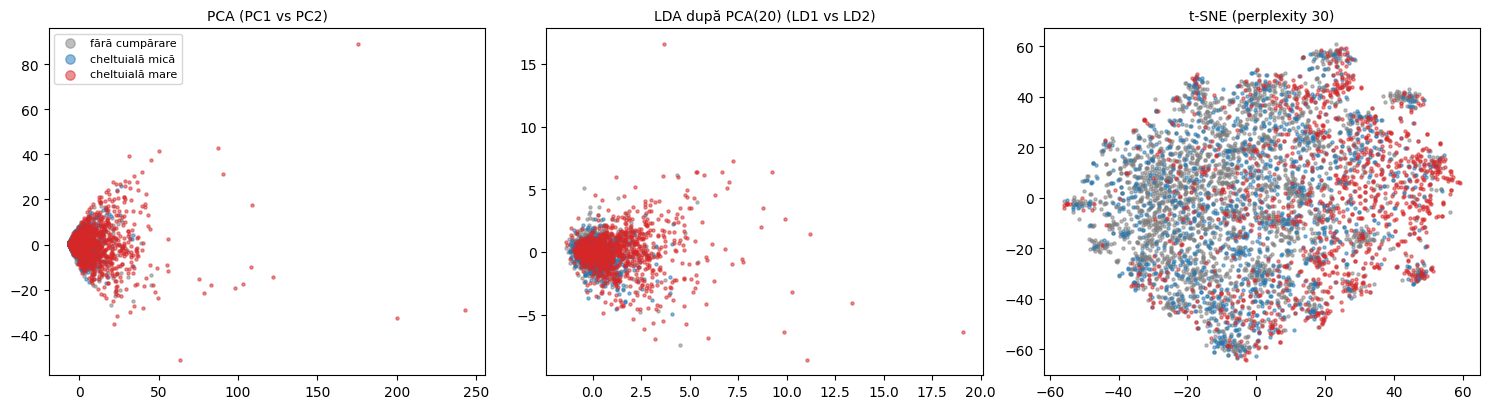

In [13]:
lda_ref = modele_lda[NUME_LDA]
LD_all = lda_ref.named_steps["lda"].transform(lda_ref.named_steps["pca"].transform(Z_all))
pca_2d = PCA(n_components=2, random_state=SEED).fit(Z_tr)
PC_all = pca_2d.transform(Z_all)

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for a, (titlu, P) in zip(ax, [("PCA (PC1 vs PC2)", PC_all), (f"LDA după PCA({KCV}) (LD1 vs LD2)", LD_all), (f"t-SNE (perplexity {PERP})", emb[PERP])]):
    for c in CLASE:
        m = (clasa.to_numpy() == c)
        a.scatter(P[m, 0], P[m, 1], s=5, alpha=0.5, color=CULORI[c], label=CLASE[c])
    a.set_title(titlu, fontsize=10)
ax[0].legend(markerscale=3, fontsize=8)
plt.tight_layout()
salveaza_fig("lab4_comparatie_2d")

In [14]:
rezumat = pd.DataFrame([
    {"metodă": f"PCA ({KCV} componente, alese prin validare)", "tip": "nesupervizat, liniar", "dimensiuni": KCV,
     "rezultat principal": f"LogReg AUC test = {rez.loc[rez['k'] == KCV, 'LogReg AUC test'].iloc[0]:.3f} (toate variabilele: {rez['LogReg AUC test'].iloc[-1]:.3f}; regula 95%: {rez.loc[rez['k'] == K95, 'LogReg AUC test'].iloc[0]:.3f})",
     "clienți noi": "da (transform)"},
    {"metodă": "PCA 2D", "tip": "nesupervizat, liniar", "dimensiuni": 2,
     "rezultat principal": f"trustworthiness = {rez_ts.loc['PCA 2D (bază)', 'trustworthiness (10 vecini)']:.3f}; varianță explicată = {pca_full.explained_variance_ratio_[:2].sum():.1%}",
     "clienți noi": "da (transform)"},
    {"metodă": f"LDA (după PCA {KCV})", "tip": "supervizat, liniar", "dimensiuni": 2,
     "rezultat principal": f"acuratețe test = {rez_lda.loc[NUME_LDA, 'acuratețe test']:.3f} (bază {baza_acc:.3f})", "clienți noi": "da (transform)"},
    {"metodă": f"t-SNE (perplexity {PERP})", "tip": "nesupervizat, neliniar", "dimensiuni": 2,
     "rezultat principal": f"trustworthiness = {rez_ts.loc[PERP, 'trustworthiness (10 vecini)']:.3f}", "clienți noi": "nu (se refac calculele)"},
]).set_index("metodă")
rezumat.to_csv(ARTEFACTE / "lab4_comparatie.csv")
display(rezumat)

,tip,dimensiuni,rezultat principal,clienți noi
metodă,,,,
"PCA (20 componente, alese prin validare)","nesupervizat, liniar",20,LogReg AUC test = 0.725 (toate variabilele: 0....,da (transform)
PCA 2D,"nesupervizat, liniar",2,trustworthiness = 0.598; varianță explicată = ...,da (transform)
LDA (după PCA 20),"supervizat, liniar",2,acuratețe test = 0.626 (bază 0.565),da (transform)
t-SNE (perplexity 30),"nesupervizat, neliniar",2,trustworthiness = 0.829,nu (se refac calculele)


### 5.2 Cum citim rezultatele
- **PCA:** pragurile din 4.1 arată cât de mult se poate comprima; 4.2 arată câte componente alege validarea față de regula de 95%; tabelul 4.3 arată dacă modelul pierde sau câștigă cu mai puține dimensiuni, iar decalajul train − test arată supraantrenarea.
- **LDA:** o acuratețe pe test apropiată de cea de pe train și peste bază înseamnă separare reală; un train mult peste test înseamnă supraantrenare (4.4 compară variantele).
- **t-SNE:** trustworthiness peste cea a PCA 2D înseamnă că păstrează mai bine vecinătățile locale. Distanțele *dintre* grupuri și dimensiunea lor în grafic **nu** se interpretează.

## 6. Implementare (Deployment)
Salvăm: (1) un `Pipeline` scalare + PCA (cu k ales prin validare), (2) un `Pipeline` scalare + PCA + LDA (proiecția unui client nou pe axele LD1/LD2), (3) coordonatele tuturor clienților în PCA, LDA și t-SNE, pentru graficele interactive din Streamlit.

In [15]:
model_pca = Pipeline([("scalare", scaler), ("pca", PCA(n_components=KCV, random_state=SEED).fit(Z_tr))])
model_lda = Pipeline([("scalare", scaler), ("pca", lda_ref.named_steps["pca"]), ("lda", lda_ref.named_steps["lda"])])
joblib.dump(model_pca, ARTEFACTE / "model_pca.joblib")
joblib.dump(model_lda, ARTEFACTE / "model_lda.joblib")

PC_dep = model_pca.named_steps["pca"].transform(Z_all)[:, :2]          # exact aceleași coordonate ca în modelul salvat (pentru clienții noi)
proiectii = pd.DataFrame({
    "clasa": clasa.map(CLASE), "set": np.where(clasa.index.isin(idx_te), "test", "train"),
    "PC1": PC_dep[:, 0], "PC2": PC_dep[:, 1], "LD1": LD_all[:, 0], "LD2": LD_all[:, 1],
    "tSNE1": emb[PERP][:, 0], "tSNE2": emb[PERP][:, 1],
}, index=clienti.index)
proiectii.index.name = "Customer ID"
proiectii.to_csv(ARTEFACTE / "lab4_proiectii.csv")
pd.DataFrame({"StockCode": M.columns, "Description": nume_produse.values}).to_csv(ARTEFACTE / "lab4_produse.csv", index=False)

info4 = {
    "dimensiuni": int(D), "k95": int(K95), "k_cv": int(KCV), "auc_cv_kcv": float(rez_cv.loc[KCV, "AUC validare (medie)"]),
    "auc_cv_k95": float(rez_cv.loc[K95, "AUC validare (medie)"]) if K95 in rez_cv.index else None,
    "auc_test_kcv": float(rez.loc[rez["k"] == KCV, "LogReg AUC test"].iloc[0]), "auc_test_toate": float(rez["LogReg AUC test"].iloc[-1]),
    "auc_test_k95": float(rez.loc[rez["k"] == K95, "LogReg AUC test"].iloc[0]), "praguri": {f"{p:.0%}": int(k) for p, k in K.items()}, "prag_produs": PRAG_PRODUS,
    "perplexity": PERP, "clienti": int(len(clienti)), "clase": {str(k): v for k, v in CLASE.items()}, "mediana_cheltuiala": float(mediana),
    "lda_acuratete_test": float(rez_lda.loc[NUME_LDA, "acuratețe test"]), "lda_acuratete_train": float(rez_lda.loc[NUME_LDA, "acuratețe train"]), "baza_acuratete": float(baza_acc),
    "trust_tsne": float(rez_ts.loc[PERP, "trustworthiness (10 vecini)"]), "trust_pca2d": float(rez_ts.loc["PCA 2D (bază)", "trustworthiness (10 vecini)"]),
    "var_pc12": float(pca_full.explained_variance_ratio_[:2].sum()),
}
(ARTEFACTE / "info_lab4.json").write_text(json.dumps(info4, ensure_ascii=False, indent=2), encoding="utf-8")

# test: reîncărcăm modelele salvate și proiectăm 3 clienți-exemplu din test
pca_inc, lda_inc = joblib.load(ARTEFACTE / "model_pca.joblib"), joblib.load(ARTEFACTE / "model_lda.joblib")
ex = X_te.iloc[:3]
iesire = pd.DataFrame(pca_inc.transform(ex)[:, :2], columns=["PC1", "PC2"], index=ex.index)
iesire[["LD1", "LD2"]] = lda_inc.transform(ex)
display(iesire)

,PC1,PC2,LD1,LD2
Customer ID,,,,
15769,0.925,3.611,0.708,2.177
15731,-6.073,-0.046,-0.819,-0.001
14466,4.092,4.215,-0.622,0.803


## 7. Concluzii și limite
- Blestemul dimensionalității se vede în date (3, tabelul coeficienților de variație) și în performanță (4.3, decalajul train − test).
- PCA e metoda de reducere deployabilă (are `transform`); numărul de componente se alege prin validare încrucișată pe train (4.2), iar regula de 95% rămâne un reper, nu un obiectiv.
- LDA servește separării claselor în 2D și se evaluează pe test; t-SNE servește vizualizării, nu producției (nu poate proiecta clienți noi).
- **Limite:** produsele sub 2% dintre clienți sunt excluse (vezi acoperirea din 2.2); clasele depind de o singură fereastră viitoare de 90 de zile; `log1p` pe cantități (un client cu 1 buc. și unul cu 10.000 buc. rămân diferiți, dar nu extrem).